# 02. E-Commerce Revenue Integrity, Payment Risk & Return Analysis

### Summary
Following the cleaning of 10,000 raw transaction records in Notebook 01, this analysis evaluates **9,852 validated orders** across 2025–2026 to answer four business questions for Finance, Operations, and Marketing:
1. **Financial Integrity:** How much artificial revenue distortion did our cleaning pipeline prevent?
2. **Payment & Return Risk:** Which payment channels drive the highest net retained revenue versus revenue loss over returns?
3. **Customer & Ticket-Value Segmentation:** How do order values and return rates vary across customer age brackets and high-ticket orders?
4. **DateTime Analysis & Gaps in Data Capturing:** When do peak order windows occur, and do missing customer emails relate with specific checkout channels(payment methods)?

## 1. Data Ingestion & Business KPIs

In [78]:
# Loading libraries and Setups
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Set up theme for visuals
sns.set_theme(style='whitegrid',context='notebook',palette='viridis',font_scale=1.05)

#Import the cleaned dataset and set up the datatypes
filepath_raw = r"./data/raw/ecommerce_orders_data.csv"
filepath_cleaned = r"./data/processed/ecommerce_orders_clean.csv"

df_raw = pd.read_csv(filepath_raw,dtype='str')
df = pd.read_csv(filepath_cleaned)
df['Order_Date'] = pd.to_datetime(df['Order_Date'],format='mixed')
df['Payment_Method'] = df['Payment_Method'].astype('category')
df['Is_Returned'] = df['Is_Returned'].astype('boolean')

Calculate Executive KPIs

In [79]:
total_orders = len(df)
valid_rev_orders = df['Order_Amount'].notna().sum()
gross_revenue = df['Order_Amount'].sum()
average_order_value = df['Order_Amount'].mean()
median_order_value =df['Order_Amount'].median()

known_returns = df.dropna(subset=['Is_Returned'])
return_rate = known_returns['Is_Returned'].mean()
returned_revenue = df.loc[df['Is_Returned'],'Order_Amount'].sum()
retained_revenue = gross_revenue - returned_revenue
email_capture_rate = df['Has_Email'].mean()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Validated Orders",
        "Gross Revenue",
        "Returned Order Value",
        "Net Retained Revenue",
        "Average Order Value",
        "Median Order Value",
        "Overall Return Rate",
        "Customer Email Capture Rate"
    ],
    "Value": [
        f"{total_orders:,}",
        f"₹{gross_revenue:,.2f}",
        f"₹{returned_revenue:,.2f}",
        f"₹{retained_revenue:,.2f}",
        f"₹{average_order_value:,.2f}",
        f"₹{median_order_value:,.2f}",
        f"{return_rate:.2%}",
        f"{email_capture_rate:.2%}"
    ]
})

print(f"{'EXECUTIVE KPI SCORECARD':*^50}")
display(kpi_summary)

*************EXECUTIVE KPI SCORECARD**************


,Metric,Value
0,Validated Orders,"9,338"
1,Gross Revenue,"₹15,413,410.14"
2,Returned Order Value,"₹2,266,066.47"
3,Net Retained Revenue,"₹13,147,343.67"
4,Average Order Value,"₹1,650.61"
5,Median Order Value,"₹1,330.16"
6,Overall Return Rate,15.06%
7,Customer Email Capture Rate,94.53%


## 2. Financial Impact of Data Cleaning

Removed a Total of 35 Placeholder Records reporting ₹349,999,999.65 false revenue.


,Columns,Total_Records,Recorded_Gross_Revenue,Average Order Value
0,Raw Data(Unfiltered),10000,"₹365,960,376.91","₹37,411.61"
1,Processed Data(Cleaned),9338,"₹15,413,410.14","₹1,650.61"


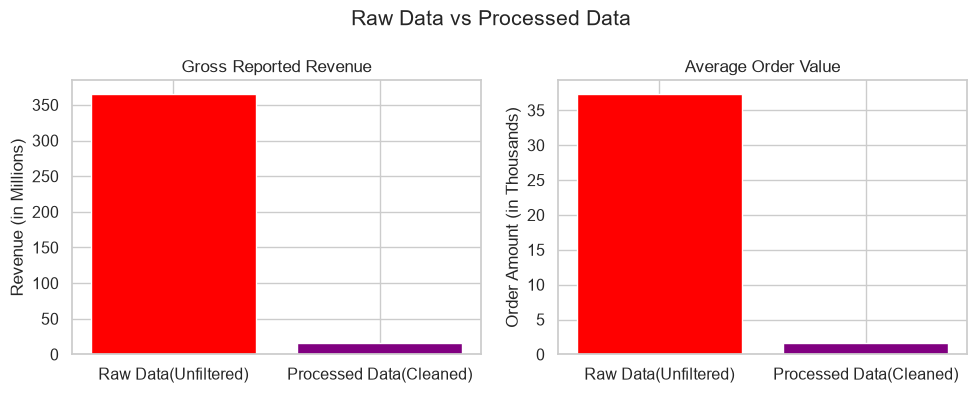

In [81]:
#Comaparing data before and after pipeline execution
raw_amounts = pd.to_numeric(
    df_raw['Order_Amount'].str.replace("[₹$ ,]","",regex=True),
    errors='coerce')
raw_total_revenue = raw_amounts.sum()
raw_average_order_value = raw_amounts.mean()
placeholder_count = (raw_amounts > 10_00_000).sum()
placeholder_revenue = raw_amounts[raw_amounts > 10_00_000].sum()

impact_df = pd.DataFrame({
    "Columns":['Raw Data(Unfiltered)','Processed Data(Cleaned)'],
    "Total_Records":[len(df_raw),len(df)],
    "Recorded_Gross_Revenue":[f"₹{raw_total_revenue:,.2f}", f"₹{gross_revenue:,.2f}"],
    "Average Order Value":[f"₹{raw_average_order_value:,.2f}",f"₹{average_order_value:,.2f}"]
    })
print(f"Removed a Total of {placeholder_count} Placeholder Records reporting ₹{placeholder_revenue:,.2f} false revenue.")
display(impact_df)

#Visualizing Raw vs Processed Data
fig,axes = plt.subplots(1,2,figsize=(10,4))
fig.suptitle("Raw Data vs Processed Data")
#Left Graph Gross Revenue
axes[0].set(title = "Gross Reported Revenue",ylabel = "Revenue (in Millions)")
axes[0].bar(
    impact_df['Columns'],
    np.array([raw_total_revenue,gross_revenue]) / 1_000_000,
    color = ['red','purple'],
)
#Right Graph Average Order Value
axes[1].set(title = "Average Order Value",ylabel='Order Amount (in Thousands)')
axes[1].bar(
    impact_df['Columns'],
    [raw_average_order_value / 1000,average_order_value / 1000],
    color = ['red','purple']
)

fig.tight_layout()
plt.show()
fig.savefig("./reports/figures/05_data_cleaning_financial_impact.jpg")
plt.close()